# Step 9 - Evaluation and Simulation
**Objective 8:** evaluate the whole system. The **models** can be evaluated with real outcomes (measured). The **retention strategy** cannot: the data holds no campaign, so nobody was ever contacted and nobody's reaction to an offer was recorded. Its effectiveness is therefore **simulated**, and every simulated number in this notebook is labelled as such.

**Input:** `data/churn_predictions_test.csv`, `data/customer_value_test.csv`, `data/retention_actions_test.csv`, `models/retention_framework.json`, `data/recommender_comparison.csv`, `data/clv_validation.csv`. Click **Run All** (about 1 minute).

**Output:** `data/simulation_by_action.csv`, `data/simulation_strategies.csv`, `data/simulation_sensitivity.csv`, `data/simulation_targeting.csv`, `models/simulation_settings.json`, `simulation_summary.txt` and charts `figures/sim_*.png`.

| Part | Status |
|---|---|
| 1-2. Evaluation scorecard: churn model, CLV model, recommender | **Measured** on real outcomes of the 1 July 2011 test snapshot |
| 3-9. Retention campaign: revenue saved, cost, break-even, sensitivity, targeting versus random | **Simulated** with assumed effects |

### How the simulation works
The data tells us what customers did **without** any campaign (they were not contacted): about 46% churned (no purchase in the next 150 days). The simulation replays 1 July 2011 as if the Step 8 actions had been carried out:

1. Each contacted customer who **really did churn** is *saved* with a probability equal to the assumed **win-back rate** of the action (for example 10% for a discount email). A saved customer then buys, bringing the revenue they would have brought had they stayed (estimated from the Step 6 value model).
2. *(Optional, switched off in the base scenario.)* Customers who return anyway may buy a little more because of the offer (an assumed **spend uplift**). It is a growth effect rather than a retention effect, it is not part of the plan's wording, and it has a very large influence on the result, so it is only added as a clearly separate sensitivity.
3. The campaign costs money: contact costs, plus the discount given to every customer who buys, including those who would have bought anyway (the "wasted" discount).
4. **Net benefit = margin x extra revenue - contact cost - discount cost.**

The win-back rate per action, the (optional) spend uplift, the profit margin and the costs are **assumptions** (section 1). The notebook therefore also shows how large each effect would need to be for the action to pay off (**break-even**), and how the result changes across a wide range of assumptions (**sensitivity**).

The win-back rate used here is the share of would-be churners that an action retains. It links to the plan's wording, "contacted customers return X% more often", through the *equivalent relative increase in return rate* shown in section 4.

## 1. Settings and assumptions

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 200
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG, MODELS = Path("data"), Path("figures"), Path("models")
for d in (FIG, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42
N_SIMS = 2000                 # Monte Carlo repetitions (who is saved is random)
N_RANDOM_ALLOC = 500          # random reallocations of the action mix (section 8)

# =============================================================================================
#  ASSUMPTIONS  - nothing below is measured; every value is a placeholder to be replaced or varied
# =============================================================================================
GROSS_MARGIN = 0.30           # ASSUMPTION: share of revenue that is profit before campaign costs
REVENUE_FLOOR = 0.05          # revenue if retained = expected 150-day revenue / max(1 - churn probability, floor)

# effect of each action:  w = share of would-be churners it retains (the retention effect used in the base scenario)
#                         s_growth = extra spend of customers who buy, only used when SPEND_UPLIFT_ON = 1
EFFECTS = pd.DataFrame([
    # action             w     s_growth
    ("PERSONAL",         0.25, 0.03),
    ("WINBACK_DISCOUNT", 0.10, 0.00),
    ("REMINDER",         0.04, 0.00),
    ("CHECKIN",          0.08, 0.02),
    ("LOYALTY",          0.03, 0.03),
    ("CROSSSELL",        0.02, 0.03),
    ("MONITOR",          0.00, 0.00),
], columns=["ActionCode", "w", "s_growth"]).set_index("ActionCode")
SPEND_UPLIFT_ON = 0.0         # base scenario = retention effect only (0). 1 switches the growth effect s_growth on; see the sensitivity in section 6

# Step 8 framework: thresholds, cut-offs and action costs come from the file written by Step 8
fw = json.loads((MODELS / "retention_framework.json").read_text(encoding="utf-8"))
ACT = pd.DataFrame(fw["actions_ASSUMED_costs_gbp"]).set_index("ActionCode")
ACT = ACT.join(EFFECTS)
display(ACT[["Action", "ContactCostGBP", "DiscountPct", "w", "s_growth"]].rename(columns={
    "w": "w: share of would-be churners retained (ASSUMED)", "s_growth": "s_growth: extra spend of buyers, optional (ASSUMED)"}))
# what-if action used only in sections 6-8: the same personal call, but without the discount
ACT_X = ACT.copy()
ACT_X.loc["PERSONAL_NODISC"] = ACT.loc["PERSONAL"]
ACT_X.loc["PERSONAL_NODISC", "Action"] = "Personal outreach without a discount (what-if)"
ACT_X.loc["PERSONAL_NODISC", "DiscountPct"] = 0.0
print(f"Gross margin {GROSS_MARGIN:.0%} (ASSUMED). Spend uplift switched {'ON' if SPEND_UPLIFT_ON else 'OFF'} in the base scenario. Step 8 settings: {fw['settings']}")

,Action,ContactCostGBP,DiscountPct,w: share of would-be churners retained (ASSUMED),"s_growth: extra spend of buyers, optional (ASSUMED)"
ActionCode,,,,,
PERSONAL,Personal outreach + tailored offer,40.000,0.100,0.250,0.030
WINBACK_DISCOUNT,Win-back email with discount,0.500,0.100,0.100,0.000
REMINDER,Reorder reminder (no discount),0.200,0.000,0.040,0.000
CHECKIN,Proactive check-in + new products,1.000,0.000,0.080,0.020
LOYALTY,Loyalty reward + new products,5.000,0.000,0.030,0.030
CROSSSELL,Cross-sell email,0.200,0.000,0.020,0.030
MONITOR,No action (monitor),0.000,0.000,0.000,0.000


Gross margin 30% (ASSUMED). Spend uplift switched OFF in the base scenario. Step 8 settings: {'P_ELEVATED': 0.35, 'N_PERSONAL': 50, 'MIN_CLV_FOR_DISCOUNT': 150}


## 2. Evaluation scorecard (measured)

The models behind the framework are evaluated on what customers **really did** in the 150 days after 1 July 2011. The numbers are recomputed here from the saved files, so they can be checked against the earlier steps.

In [2]:
churn = pd.read_csv(DATA / "churn_predictions_test.csv")
y, p = churn["Churn"].to_numpy(), churn["ChurnProbability"].to_numpy()

# ---- churn model (Step 4)
THR = fw["settings"]["P_ELEVATED"]
pred = p >= THR
tp, fp, fn = (pred & (y == 1)).sum(), (pred & (y == 0)).sum(), (~pred & (y == 1)).sum()
prec, rec = tp / (tp + fp), tp / (tp + fn)
top20 = np.argsort(-p)[: int(0.2 * len(p))]
bins = np.clip((p * 10).astype(int), 0, 9)
ece = sum((bins == b).mean() * abs(p[bins == b].mean() - y[bins == b].mean()) for b in range(10) if (bins == b).any())
rows = [
    ("Churn model (Step 4)", "ROC-AUC", roc_auc_score(y, p), "ranking quality; 0.5 = random"),
    ("Churn model (Step 4)", "PR-AUC", average_precision_score(y, p), f"churn rate is {y.mean():.1%}, so a random model scores about that"),
    ("Churn model (Step 4)", f"Precision / recall at threshold {THR}", f"{prec:.3f} / {rec:.3f}", f"F1 {2 * prec * rec / (prec + rec):.3f}"),
    ("Churn model (Step 4)", "Churners reached by contacting the top 20% by risk", y[top20].sum() / y.sum(), "random targeting would reach 20%"),
    ("Churn model (Step 4)", "Brier score / calibration error (ECE)", f"{brier_score_loss(y, p):.3f} / {ece:.3f}", "lower is better"),
]

# ---- CLV model (Step 6)
cv = pd.read_csv(DATA / "clv_validation.csv")
allc = cv[cv["Group"] == "All active customers"].set_index("Cutoff")
for cut, r in allc.iterrows():
    rows.append(("CLV model (Step 6)", f"Predicted / actual purchase days, cut-off {cut}", r["PurchaseRatio"],
                 "1.00 = perfectly calibrated; the model has no seasonal term"))

# ---- recommender (Step 7)
rc = pd.read_csv(DATA / "recommender_comparison.csv")
disc_ = rc[rc["Setting"].str.startswith("Discovery")].set_index("Method")
best = disc_["Precision@10 [95% CI]"].str.split(" ").str[0].astype(float).drop("Popularity").idxmax()
rows.append(("Recommender (Step 7)", f"Precision@10, {best} (new products only)", disc_.loc[best, "Precision@10 [95% CI]"], "95% CI in brackets"))
rows.append(("Recommender (Step 7)", "Precision@10, popularity baseline", disc_.loc["Popularity", "Precision@10 [95% CI]"], ""))
rows.append(("Recommender (Step 7)", f"Hit rate@10, {best} vs popularity", f"{disc_.loc[best, 'Hit rate@10']:.3f} vs {disc_.loc['Popularity', 'Hit rate@10']:.3f}", "share of customers with at least one correct recommendation"))

scorecard = pd.DataFrame(rows, columns=["Component", "Metric", "Value", "Note"])
scorecard["Value"] = scorecard["Value"].map(lambda v: f"{v:.3f}" if isinstance(v, float) else v)
display(scorecard)
print("All values above are MEASURED on the 1 July 2011 test snapshot; the retention campaign below is SIMULATED.")

,Component,Metric,Value,Note
0,Churn model (Step 4),ROC-AUC,0.775,ranking quality; 0.5 = random
1,Churn model (Step 4),PR-AUC,0.696,"churn rate is 45.7%, so a random model scores ..."
2,Churn model (Step 4),Precision / recall at threshold 0.35,0.577 / 0.939,F1 0.715
3,Churn model (Step 4),Churners reached by contacting the top 20% by ...,0.312,random targeting would reach 20%
4,Churn model (Step 4),Brier score / calibration error (ECE),0.193 / 0.050,lower is better
5,CLV model (Step 6),"Predicted / actual purchase days, cut-off 2010...",1.586,1.00 = perfectly calibrated; the model has no ...
6,CLV model (Step 6),"Predicted / actual purchase days, cut-off 2011...",0.976,1.00 = perfectly calibrated; the model has no ...
7,Recommender (Step 7),"Precision@10, Matrix factorisation (SVD) (new ...","0.087 [0.082, 0.092]",95% CI in brackets
8,Recommender (Step 7),"Precision@10, popularity baseline","0.049 [0.046, 0.053]",
9,Recommender (Step 7),"Hit rate@10, Matrix factorisation (SVD) vs pop...",0.483 vs 0.342,share of customers with at least one correct r...


All values above are MEASURED on the 1 July 2011 test snapshot; the retention campaign below is SIMULATED.


## 3. Economic inputs for every customer

For each customer the simulation needs, besides the actual outcome (`Churn`, `Outcome_FutureSpend`):

* **Revenue if retained** = expected 150-day revenue from the Step 6 value model, divided by the probability of buying in the window (`1 - churn probability`). This is the revenue a customer would bring *given that they buy*, and is what a "saved" churner is worth. It is a model estimate because the real revenue of a churner who had stayed is unobservable.
* **Typical order value** (Step 6), used for the discount cost.
* **Actual spend** of customers who did return (observed).

The check below compares the revenue-if-retained estimate with the **actual spend of customers who really returned**, to see whether it is a fair value for a saved customer.

In [3]:
val = pd.read_csv(DATA / "customer_value_test.csv")
act0 = pd.read_csv(DATA / "retention_actions_test.csv")
D = (act0[["CustomerID", "Segment", "ActionCode", "ChurnProbability", "RiskTier", "CLV12m", "ValueTier", "ValueAtRisk"]]
     .merge(churn[["CustomerID", "Churn", "Outcome_FutureSpend"]], on="CustomerID", validate="1:1")
     .merge(val[["CustomerID", "ExpRevenue150", "ExpValuePerPurchase"]], on="CustomerID", validate="1:1"))
assert len(D) == len(churn) == 4313 and D["CustomerID"].is_unique
D["Rev"] = D["ExpRevenue150"] / (1 - D["ChurnProbability"]).clip(lower=REVENUE_FLOOR)     # revenue if the customer buys
D = D.rename(columns={"Outcome_FutureSpend": "Spend", "ExpValuePerPurchase": "V"})

ret = D[D["Churn"] == 0]
print(f"Customers who really returned: {len(ret):,}. Their actual total spend {ret['Spend'].sum():,.0f}; estimated by the revenue-if-retained formula {ret['Rev'].sum():,.0f} "
      f"(actual / estimate = {ret['Spend'].sum() / ret['Rev'].sum():.2f}).")
print("By segment (average per returning customer):")
display(ret.groupby("Segment").agg(Customers=("Spend", "size"), ActualSpend=("Spend", "mean"), EstimatedRevenue=("Rev", "mean")))
print(f"Rank correlation between estimate and actual spend among returners: {ret[['Rev', 'Spend']].corr(method='spearman').iloc[0, 1]:.2f}")
ch = D[D["Churn"] == 1]
print(f"\nCustomers who really churned: {len(ch):,}; the revenue they would have brought if retained is estimated at {ch['Rev'].sum():,.0f} in total "
      f"({ch['Rev'].mean():,.0f} on average; the 10 largest account for {ch.nlargest(10, 'Rev')['Rev'].sum() / ch['Rev'].sum():.0%}).")

Customers who really returned: 2,344. Their actual total spend 3,587,908; estimated by the revenue-if-retained formula 3,243,478 (actual / estimate = 1.11).
By segment (average per returning customer):


,Customers,ActualSpend,EstimatedRevenue
Segment,,,
At-risk regulars,738,890.225,968.199
Champions,650,"3,673.337","2,935.551"
Lapsed low-frequency customers,487,424.881,483.290
Recent / developing customers,469,717.134,821.912


Rank correlation between estimate and actual spend among returners: 0.67

Customers who really churned: 1,969; the revenue they would have brought if retained is estimated at 1,248,663 in total (634 on average; the 10 largest account for 5%).


## 4. The simulation engine and the base scenario

For every customer the **expected** result of the action they are given is computed from the assumptions and the real outcome (churned or returned), following the four steps described at the top. Because everything is linear in the win-back rate, the expected values are exact; the Monte Carlo runs add the randomness of *who* is saved, which gives uncertainty intervals.

Contact and discount costs follow the Step 8 action catalogue (its placeholder costs). The discount is assumed to be used on one typical order by **every** contacted customer who buys, including those who would have bought anyway, which is the conservative (expensive) case.

In [4]:
def components(D, codes, scale=1.0, margin=GROSS_MARGIN, cmult=1.0, dmult=1.0, rmult=1.0, uplift=None, act=None):
    """Expected economics per customer if customer i receives action codes[i] (expectation over who is saved)."""
    uplift = SPEND_UPLIFT_ON if uplift is None else uplift
    act = ACT_X if act is None else act
    codes = pd.Series(np.asarray(codes), index=D.index)
    w = (codes.map(act["w"]) * scale).clip(0, 1).to_numpy()
    s = (codes.map(act["s_growth"]) * uplift * scale).to_numpy()
    cost = codes.map(act["ContactCostGBP"]).to_numpy() * cmult
    disc = codes.map(act["DiscountPct"]).to_numpy() * dmult
    churned = D["Churn"].to_numpy()
    rev = D["Rev"].to_numpy() * rmult
    saved_rev = w * churned * rev                                              # revenue of the churners that are won back
    uplift_rev = s * ((1 - churned) * D["Spend"].to_numpy() + churned * w * rev)  # extra spend of customers who buy
    disc_cost = disc * D["V"].to_numpy() * ((1 - churned) + churned * w)       # discount on one typical order of every buyer
    out = pd.DataFrame({"Action": codes.to_numpy(), "Contacted": (codes != "MONITOR").to_numpy().astype(int),
                        "SavedCustomers": w * churned, "SavedRevenue": saved_rev, "UpliftRevenue": uplift_rev,
                        "ContactCost": cost, "DiscountCost": disc_cost}, index=D.index)
    out["Net"] = margin * (out["SavedRevenue"] + out["UpliftRevenue"]) - out["ContactCost"] - out["DiscountCost"]
    return out


def by_action(comp, D):
    g = comp.groupby("Action")
    t = g[["Contacted", "SavedCustomers", "SavedRevenue", "UpliftRevenue", "ContactCost", "DiscountCost", "Net"]].sum()
    t.insert(0, "Customers", g.size())
    grp_churn = D.groupby(comp["Action"])["Churn"].mean()
    t["BaselineChurnRate"] = grp_churn
    t["Cost"] = t["ContactCost"] + t["DiscountCost"]
    t["ROI"] = np.where(t["Cost"] > 0, t["Net"] / t["Cost"], np.nan)
    return t.reindex(ACT.index).fillna(0)


comp0 = components(D, D["ActionCode"])
base = by_action(comp0, D)
base.insert(0, "ActionName", ACT["Action"])
# the plan's wording: "contacted customers return X% more often"
base["EquivalentRelativeIncreaseInReturnRate"] = ACT["w"] * base["BaselineChurnRate"] / (1 - base["BaselineChurnRate"]).replace(0, np.nan)
display(base[["ActionName", "Customers", "BaselineChurnRate", "SavedCustomers", "SavedRevenue", "UpliftRevenue", "ContactCost", "DiscountCost", "Net", "ROI",
              "EquivalentRelativeIncreaseInReturnRate"]])

tot = comp0[["SavedCustomers", "SavedRevenue", "UpliftRevenue", "ContactCost", "DiscountCost", "Net"]].sum()
cost_tot = tot["ContactCost"] + tot["DiscountCost"]
print(f"\nSIMULATED base scenario, {len(D):,} customers: {tot['SavedCustomers']:,.0f} churners won back, extra revenue {tot['SavedRevenue'] + tot['UpliftRevenue']:,.0f} "
      f"(margin {GROSS_MARGIN:.0%} = {GROSS_MARGIN * (tot['SavedRevenue'] + tot['UpliftRevenue']):,.0f}), contact cost {tot['ContactCost']:,.0f}, discount cost {tot['DiscountCost']:,.0f}")
print(f"-> net benefit {tot['Net']:,.0f}, return on campaign spend {tot['Net'] / cost_tot:.2f} per GBP 1 spent.")
print("The last column translates the assumed win-back rate into 'contacted customers return X% more often' (relative to their baseline return rate).")

,ActionName,Customers,BaselineChurnRate,SavedCustomers,SavedRevenue,UpliftRevenue,ContactCost,DiscountCost,Net,ROI,EquivalentRelativeIncreaseInReturnRate
ActionCode,,,,,,,,,,,
PERSONAL,Personal outreach + tailored offer,50,0.360,4.500,"20,494.948",0.000,"2,000.000","5,059.236",-910.752,-0.129,0.141
WINBACK_DISCOUNT,Win-back email with discount,781,0.703,54.900,"28,174.738",0.000,390.500,"9,519.256","-1,457.335",-0.147,0.237
REMINDER,Reorder reminder (no discount),1099,0.678,29.800,"13,987.487",0.000,219.800,0.000,"3,976.446",18.091,0.084
CHECKIN,Proactive check-in + new products,302,0.507,12.240,"12,399.800",0.000,302.000,0.000,"3,417.940",11.318,0.082
LOYALTY,Loyalty reward + new products,771,0.078,1.800,"2,726.895",0.000,"3,855.000",0.000,"-3,036.931",-0.788,0.003
CROSSSELL,Cross-sell email,1009,0.290,5.860,"4,506.656",0.000,201.800,0.000,"1,150.197",5.700,0.008
MONITOR,No action (monitor),301,0.502,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000



SIMULATED base scenario, 4,313 customers: 109 churners won back, extra revenue 82,291 (margin 30% = 24,687), contact cost 6,969, discount cost 14,578
-> net benefit 3,140, return on campaign spend 0.15 per GBP 1 spent.
The last column translates the assumed win-back rate into 'contacted customers return X% more often' (relative to their baseline return rate).


In [5]:
# ---- Monte Carlo: who is saved is random
rng = np.random.default_rng(SEED)
sim_net = np.zeros((N_SIMS, len(ACT)))
for j, a in enumerate(ACT.index):
    g = D[D["ActionCode"] == a]
    if g.empty:
        continue
    w, s = ACT.loc[a, "w"], ACT.loc[a, "s_growth"] * SPEND_UPLIFT_ON
    chg = g[g["Churn"] == 1]
    X = rng.random((N_SIMS, len(chg))) < w                                    # saved or not, per churner and run
    saved_rev = X @ chg["Rev"].to_numpy()
    saved_v = X @ chg["V"].to_numpy()
    ret_g = g[g["Churn"] == 0]
    uplift = s * (ret_g["Spend"].sum() + saved_rev)
    disc_cost = ACT.loc[a, "DiscountPct"] * (ret_g["V"].sum() + saved_v)
    sim_net[:, j] = GROSS_MARGIN * (saved_rev + uplift) - ACT.loc[a, "ContactCostGBP"] * len(g) - disc_cost
sim_total = sim_net.sum(axis=1)
lo, hi = np.percentile(sim_total, [5, 95])
print(f"SIMULATED net benefit of the campaign, {N_SIMS:,} runs: mean {sim_total.mean():,.0f}, 5th-95th percentile {lo:,.0f} to {hi:,.0f}; "
      f"net benefit is positive in {(sim_total > 0).mean():.0%} of runs.")
print("These intervals only reflect WHO is saved (luck) for the assumed win-back rates; uncertainty about the rates themselves is covered by sections 5 and 6.")
mc = pd.DataFrame({"mean": sim_net.mean(axis=0), "p5": np.percentile(sim_net, 5, axis=0), "p95": np.percentile(sim_net, 95, axis=0)}, index=ACT.index)
display(mc.round(0).T)

SIMULATED net benefit of the campaign, 2,000 runs: mean 3,092, 5th-95th percentile -1,876 to 9,678; net benefit is positive in 81% of runs.
These intervals only reflect WHO is saved (luck) for the assumed win-back rates; uncertainty about the rates themselves is covered by sections 5 and 6.


ActionCode,PERSONAL,WINBACK_DISCOUNT,REMINDER,CHECKIN,LOYALTY,CROSSSELL,MONITOR
mean,-979.000,"-1,470.000","3,957.000","3,430.000","-3,013.000","1,168.000",0.000
p5,"-4,918.000","-2,941.000","2,714.000","1,774.000","-3,855.000",303.000,0.000
p95,"5,031.000",44.000,"5,255.000","5,276.000","-1,724.000","2,189.000",0.000


## 5. Break-even: how effective must an action be to pay off?

Because the true effect of an action is unknown, the most useful question is the reverse one: **what win-back rate would make each action break even** (net benefit zero), given the actual group of customers it targets, the assumed margin and the costs? The assumed rate can then be judged against it.

In [6]:
def breakeven_w(D, codes, a, margin=GROSS_MARGIN, uplift=None, disc=None):
    g = D[np.asarray(codes) == a]
    if g.empty:
        return np.nan
    ch_, rt_ = g[g["Churn"] == 1], g[g["Churn"] == 0]
    uplift = SPEND_UPLIFT_ON if uplift is None else uplift
    s, cost = ACT.loc[a, "s_growth"] * uplift, ACT.loc[a, "ContactCostGBP"]
    disc = ACT.loc[a, "DiscountPct"] if disc is None else disc
    num = cost * len(g) + disc * rt_["V"].sum() - margin * s * rt_["Spend"].sum()       # cost that must be recovered at w = 0
    den = margin * (1 + s) * ch_["Rev"].sum() - disc * ch_["V"].sum()                    # net gain per unit of win-back rate
    if den <= 0:
        return np.inf                                                                    # can never pay off
    return max(num / den, 0.0)                                                           # 0 = pays even without any win-back


be = pd.DataFrame({"ActionName": ACT["Action"], "AssumedW": ACT["w"],
                   "BreakEvenW": [breakeven_w(D, D["ActionCode"], a) for a in ACT.index],
                   "BreakEvenW_ifSpendUpliftOn": [breakeven_w(D, D["ActionCode"], a, uplift=1.0) for a in ACT.index]}, index=ACT.index)
be["Verdict"] = np.select([be["BreakEvenW"] == 0, be["AssumedW"] >= be["BreakEvenW"]], ["pays even with no win-back (cost recovered by extra spend)", "pays under the assumed rate"],
                          default="below break-even under the assumed rate")
be.loc["MONITOR", "Verdict"] = "no spend"
# what-if: the same personal call without the discount
be.loc["PERSONAL_NODISC"] = ["Personal outreach without a discount (what-if)", ACT.loc["PERSONAL", "w"],
                             breakeven_w(D, D["ActionCode"], "PERSONAL", disc=0.0), breakeven_w(D, D["ActionCode"], "PERSONAL", uplift=1.0, disc=0.0), ""]
be.loc["PERSONAL_NODISC", "Verdict"] = ("would pay under the assumed rate" if float(be.loc["PERSONAL_NODISC", "AssumedW"]) >= float(be.loc["PERSONAL_NODISC", "BreakEvenW"])
                                         else "below break-even under the assumed rate")
be[["AssumedW", "BreakEvenW", "BreakEvenW_ifSpendUpliftOn"]] = be[["AssumedW", "BreakEvenW", "BreakEvenW_ifSpendUpliftOn"]].astype(float)
display(be)

# verification: net at the break-even rate is zero (for actions that have a positive, finite break-even rate)
checked = []
for a in ACT.index[:-1]:
    w_star = be.loc[a, "BreakEvenW"]
    if not (0 < w_star < np.inf):
        continue
    save = ACT.loc[a, "w"]
    ACT.loc[a, "w"] = w_star
    net_at = components(D, D["ActionCode"], act=ACT).loc[D["ActionCode"] == a, "Net"].sum()
    ACT.loc[a, "w"] = save
    assert abs(net_at) < 1e-6 * max(1, base.loc[a, "Cost"]), f"break-even check failed for {a}"
    checked.append(a)
print(f"Break-even check passed: net benefit at the break-even rate is zero for {', '.join(checked)}  ✓")
print("'BreakEvenW' is the retention-only break-even rate (the base scenario). 'BreakEvenW_ifSpendUpliftOn' shows how much lower it would be "
      "if the optional spend uplift of the action were real; 0% means the action would pay even if it won back nobody.")
for a in list(ACT.index[:-1]) + ["PERSONAL_NODISC"]:
    r = be.loc[a]
    print(f"* {r['ActionName']}: break-even win-back rate {r['BreakEvenW']:.1%} (if the spend uplift were real {r['BreakEvenW_ifSpendUpliftOn']:.1%}) against {r['AssumedW']:.1%} assumed -> {r['Verdict']}.")

,ActionName,AssumedW,BreakEvenW,BreakEvenW_ifSpendUpliftOn,Verdict
ActionCode,,,,,
PERSONAL,Personal outreach + tailored offer,0.250,0.295,0.258,below break-even under the assumed rate
WINBACK_DISCOUNT,Win-back email with discount,0.100,0.122,0.122,below break-even under the assumed rate
REMINDER,Reorder reminder (no discount),0.040,0.002,0.002,pays under the assumed rate
CHECKIN,Proactive check-in + new products,0.080,0.006,0.000,pays under the assumed rate
LOYALTY,Loyalty reward + new products,0.030,0.141,0.000,below break-even under the assumed rate
CROSSSELL,Cross-sell email,0.020,0.003,0.000,pays under the assumed rate
MONITOR,No action (monitor),0.000,0.000,0.000,no spend
PERSONAL_NODISC,Personal outreach without a discount (what-if),0.250,0.081,0.057,would pay under the assumed rate


Break-even check passed: net benefit at the break-even rate is zero for PERSONAL, WINBACK_DISCOUNT, REMINDER, CHECKIN, LOYALTY, CROSSSELL  ✓
'BreakEvenW' is the retention-only break-even rate (the base scenario). 'BreakEvenW_ifSpendUpliftOn' shows how much lower it would be if the optional spend uplift of the action were real; 0% means the action would pay even if it won back nobody.
* Personal outreach + tailored offer: break-even win-back rate 29.5% (if the spend uplift were real 25.8%) against 25.0% assumed -> below break-even under the assumed rate.
* Win-back email with discount: break-even win-back rate 12.2% (if the spend uplift were real 12.2%) against 10.0% assumed -> below break-even under the assumed rate.
* Reorder reminder (no discount): break-even win-back rate 0.2% (if the spend uplift were real 0.2%) against 4.0% assumed -> pays under the assumed rate.
* Proactive check-in + new products: break-even win-back rate 0.6% (if the spend uplift were real 0.0%) against 8.0% as

## 6. Sensitivity: how much do the conclusions depend on the assumptions?

**Grid.** Total net benefit when all effect sizes are scaled by a factor (0 = the campaign changes nothing, 1 = base assumptions, 2 = twice as effective) and for different margins. The 0 column shows the pure cost of the campaign.

**Tornado.** The assumptions are changed **one at a time** to a low and a high value, to see which matter most:

| Assumption | Low | High |
|---|---|---|
| Effect sizes (win-back rate and spend uplift) | x 0.5 | x 1.5 |
| Gross margin | 20% | 40% |
| Contact costs | x 0.5 | x 2 |
| Discount size | 5% | 15% |
| Value of a saved customer (revenue if retained) | x 0.8 | x 1.2 |
| Personal-outreach capacity | 25 | 100 |

In [7]:
SCALES = [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
MARGINS = [0.15, 0.20, 0.30, 0.40, 0.50]
grid = pd.DataFrame({f"margin {m:.0%}": [components(D, D["ActionCode"], scale=s, margin=m)["Net"].sum() for s in SCALES] for m in MARGINS},
                    index=[f"effects x{s:g}" for s in SCALES])
print("SIMULATED total net benefit (GBP) by effect scale (rows) and gross margin (columns):")
display(grid.round(0))


# ---- re-apply the Step 8 rules (for the capacity sensitivity); must reproduce the Step 8 file exactly
cut_med, cut_high = fw["risk_tier_cutoffs"]["medium_from"], fw["risk_tier_cutoffs"]["high_from"]
clv_med, clv_high = fw["value_tier_cutoffs_clv12m"]["medium_from"], fw["value_tier_cutoffs_clv12m"]["high_from"]


def assign_actions(d, p_elevated, n_personal, min_clv_discount):
    """The Step 8 rule table (same logic as the retention notebook)."""
    risk = np.select([d["ChurnProbability"] >= cut_high, d["ChurnProbability"] >= cut_med], ["High", "Medium"], default="Low")
    value = np.select([d["CLV12m"] >= clv_high, d["CLV12m"] >= clv_med], ["High", "Medium"], default="Low")
    var = d["ChurnProbability"] * d["CLV12m"]
    elevated = d["ChurnProbability"] >= p_elevated
    var_rank = var.where(elevated).rank(ascending=False, method="first")
    r_high, r_med = risk == "High", risk == "Medium"
    v_high, v_med, v_low = value == "High", value == "Medium", value == "Low"
    conds = [elevated & (var_rank <= n_personal), r_high & (d["CLV12m"] >= min_clv_discount), r_high,
             (r_med & ~v_low) | (elevated & v_high), r_med, v_high, v_med]
    return pd.Series(np.select(conds, ["PERSONAL", "WINBACK_DISCOUNT", "REMINDER", "CHECKIN", "REMINDER", "LOYALTY", "CROSSSELL"], default="MONITOR"), index=d.index)


S8 = fw["settings"]
reproduced = assign_actions(D, S8["P_ELEVATED"], S8["N_PERSONAL"], S8["MIN_CLV_FOR_DISCOUNT"])
assert (reproduced == D["ActionCode"]).all(), "re-applied rules differ from retention_actions_test.csv"
print("\nThe Step 8 rules, re-applied here, reproduce retention_actions_test.csv exactly  ✓")

base_net = comp0["Net"].sum()
torn = []
def add(name, low_label, high_label, f_low, f_high):
    torn.append({"Assumption": name, "LowSetting": low_label, "HighSetting": high_label, "NetAtLow": f_low, "NetAtHigh": f_high})

add("Effect sizes", "x0.5", "x1.5", components(D, D["ActionCode"], scale=0.5)["Net"].sum(), components(D, D["ActionCode"], scale=1.5)["Net"].sum())
add("Gross margin", "20%", "40%", components(D, D["ActionCode"], margin=0.2)["Net"].sum(), components(D, D["ActionCode"], margin=0.4)["Net"].sum())
add("Contact costs", "x2", "x0.5", components(D, D["ActionCode"], cmult=2)["Net"].sum(), components(D, D["ActionCode"], cmult=0.5)["Net"].sum())
add("Discount size", "15%", "5%", components(D, D["ActionCode"], dmult=1.5)["Net"].sum(), components(D, D["ActionCode"], dmult=0.5)["Net"].sum())
add("Spend uplift of growth actions (optional)", "off (base)", "on, as in table", components(D, D["ActionCode"], uplift=0.0)["Net"].sum(), components(D, D["ActionCode"], uplift=1.0)["Net"].sum())
add("Value of a saved customer", "x0.8", "x1.2", components(D, D["ActionCode"], rmult=0.8)["Net"].sum(), components(D, D["ActionCode"], rmult=1.2)["Net"].sum())
net_cap = {n: components(D, assign_actions(D, S8["P_ELEVATED"], n, S8["MIN_CLV_FOR_DISCOUNT"]))["Net"].sum() for n in (25, 50, 100, 200)}
add("Personal-outreach capacity", "25", "100", net_cap[25], net_cap[100])
tornado = pd.DataFrame(torn)
tornado["Range"] = (tornado["NetAtHigh"] - tornado["NetAtLow"]).abs()
tornado = tornado.sort_values("Range", ascending=False).reset_index(drop=True)
print(f"\nSIMULATED net benefit with base assumptions: {base_net:,.0f}. One assumption at a time:")
display(tornado[["Assumption", "LowSetting", "NetAtLow", "HighSetting", "NetAtHigh"]].round(0))
print("Net benefit by personal-outreach capacity:", {n: round(v) for n, v in net_cap.items()})

SIMULATED total net benefit (GBP) by effect scale (rows) and gross margin (columns):


,margin 15%,margin 20%,margin 30%,margin 40%,margin 50%
effects x0,"-18,652.000","-18,652.000","-18,652.000","-18,652.000","-18,652.000"
effects x0.25,"-16,290.000","-15,262.000","-13,204.000","-11,147.000","-9,090.000"
effects x0.5,"-13,928.000","-11,871.000","-7,756.000","-3,642.000",473.000
effects x0.75,"-11,566.000","-8,480.000","-2,308.000","3,863.000","10,035.000"
effects x1,"-9,204.000","-5,089.000","3,140.000","11,369.000","19,598.000"
effects x1.5,"-4,480.000","1,692.000","14,036.000","26,379.000","38,723.000"
effects x2,244.000,"8,473.000","24,932.000","41,390.000","57,848.000"



The Step 8 rules, re-applied here, reproduce retention_actions_test.csv exactly  ✓

SIMULATED net benefit with base assumptions: 3,140. One assumption at a time:


,Assumption,LowSetting,NetAtLow,HighSetting,NetAtHigh
0,Spend uplift of growth actions (optional),off (base),"3,140.000","on, as in table","32,355.000"
1,Effect sizes,x0.5,"-7,756.000",x1.5,"14,036.000"
2,Gross margin,20%,"-5,089.000",40%,"11,369.000"
3,Discount size,15%,"-4,150.000",5%,"10,429.000"
4,Contact costs,x2,"-3,830.000",x0.5,"6,624.000"
5,Value of a saved customer,x0.8,"-1,798.000",x1.2,"8,077.000"
6,Personal-outreach capacity,25,"4,800.000",100,405.000


Net benefit by personal-outreach capacity: {25: 4800, 50: 3140, 100: 405, 200: -4787}


## 7. Does targeting by risk and value beat random targeting?

The plan asks to compare targeting by churn risk and value with random targeting. To isolate the **targeting**, the same single action is given to *N* customers chosen in four ways, and the simulated net benefit is compared:

* **Random** (the expected result of picking customers at random),
* **By churn risk** (highest churn probability first),
* **By value** (highest CLV first),
* **By value at risk** (churn probability x CLV, the Step 8 priority index).

Three actions are shown: the cheap **discount email** (assumed win-back rate 10%), the costly **personal call** as defined in Step 8 (25%, with a 10% discount), and the same call **without the discount** (what-if). Note that a discount is paid by *every* customer who buys, including those who would have bought anyway, and its cost grows with the customer's order size; for large customers who mostly return anyway, targeting by value can therefore be worse than random for a discounted action.

In [8]:
TARGET_ACTIONS = ("WINBACK_DISCOUNT", "PERSONAL", "PERSONAL_NODISC")


def per_customer_net(action):
    return components(D, np.full(len(D), action))["Net"].to_numpy()


scores = {"By value at risk": D["ChurnProbability"] * D["CLV12m"], "By churn risk": D["ChurnProbability"], "By value (CLV)": D["CLV12m"]}
Ns = np.unique(np.r_[0, np.arange(25, 301, 25), np.arange(400, len(D) + 1, 100), len(D)])
trows = []
for action in TARGET_ACTIONS:
    net_i = per_customer_net(action)
    for name, sc in scores.items():
        cum = np.cumsum(net_i[np.argsort(-sc.to_numpy(), kind="stable")])
        for n in Ns:
            trows.append({"Action": action, "Targeting": name, "N": int(n), "Net": 0.0 if n == 0 else cum[n - 1]})
    for n in Ns:
        trows.append({"Action": action, "Targeting": "Random (expected)", "N": int(n), "Net": net_i.sum() * n / len(D)})
targeting = pd.DataFrame(trows)
targeting.to_csv(DATA / "simulation_targeting.csv", index=False)

for action in TARGET_ACTIONS:
    t = targeting[targeting["Action"] == action]
    print(f"\n{ACT_X.loc[action, 'Action']}: SIMULATED net benefit (GBP) when the action is given to N customers")
    piv = t[t["N"].isin([50, 100, 200, 500, 1000, 2000, len(D)])].pivot(index="N", columns="Targeting", values="Net")[["By value at risk", "By churn risk", "By value (CLV)", "Random (expected)"]]
    display(piv.round(0))
    best_ = t.loc[t.groupby("Targeting")["Net"].idxmax()].set_index("Targeting")[["N", "Net"]]
    print("Best N and the net benefit there:", {k: (int(r.N), round(r.Net)) for k, r in best_.iterrows()})
    n50 = t[t["N"] == 50].set_index("Targeting")["Net"]
    print(f"At N = 50: value at risk {n50['By value at risk']:,.0f}, churn risk {n50['By churn risk']:,.0f}, CLV {n50['By value (CLV)']:,.0f}, random {n50['Random (expected)']:,.0f}.")


Win-back email with discount: SIMULATED net benefit (GBP) when the action is given to N customers


Targeting,By value at risk,By churn risk,By value (CLV),Random (expected)
N,,,,
50,"-8,801.000",16.000,"-8,388.000",-859.000
100,"-12,292.000",367.000,"-12,311.000","-1,718.000"
200,"-15,931.000",520.000,"-18,358.000","-3,435.000"
500,"-25,961.000",-152.000,"-32,894.000","-8,589.000"
1000,"-37,871.000","-2,427.000","-48,896.000","-17,177.000"
2000,"-53,862.000","-7,700.000","-66,286.000","-34,355.000"
4313,"-74,086.000","-74,086.000","-74,086.000","-74,086.000"


Best N and the net benefit there: {'By churn risk': (150, 748), 'By value (CLV)': (0, 0), 'By value at risk': (0, 0), 'Random (expected)': (0, 0)}
At N = 50: value at risk -8,801, churn risk 16, CLV -8,388, random -859.

Personal outreach + tailored offer: SIMULATED net benefit (GBP) when the action is given to N customers


Targeting,By value at risk,By churn risk,By value (CLV),Random (expected)
N,,,,
50,"-8,419.000","-1,251.000","-9,488.000","-2,307.000"
100,"-13,091.000","-1,978.000","-14,896.000","-4,615.000"
200,"-18,348.000","-4,254.000","-24,162.000","-9,229.000"
500,"-36,290.000","-13,136.000","-48,460.000","-23,073.000"
1000,"-62,174.000","-29,091.000","-80,280.000","-46,146.000"
2000,"-106,944.000","-60,542.000","-125,808.000","-92,293.000"
4313,"-199,029.000","-199,029.000","-199,029.000","-199,029.000"


Best N and the net benefit there: {'By churn risk': (0, 0), 'By value (CLV)': (0, 0), 'By value at risk': (0, 0), 'Random (expected)': (0, 0)}
At N = 50: value at risk -8,419, churn risk -1,251, CLV -9,488, random -2,307.

Personal outreach without a discount (what-if): SIMULATED net benefit (GBP) when the action is given to N customers


Targeting,By value at risk,By churn risk,By value (CLV),Random (expected)
N,,,,
50,"2,755.000",-516.000,-169.000,-914.000
100,"2,298.000",-652.000,"-1,208.000","-1,829.000"
200,"2,917.000","-1,423.000","-3,855.000","-3,657.000"
500,"-1,210.000","-5,501.000","-11,794.000","-9,143.000"
1000,"-9,736.000","-12,655.000","-24,131.000","-18,287.000"
2000,"-28,200.000","-24,803.000","-41,483.000","-36,573.000"
4313,"-78,870.000","-78,870.000","-78,870.000","-78,870.000"


Best N and the net benefit there: {'By churn risk': (0, 0), 'By value (CLV)': (25, 831), 'By value at risk': (175, 2944), 'Random (expected)': (0, 0)}
At N = 50: value at risk 2,755, churn risk -516, CLV -169, random -914.


## 8. The framework against simple alternatives

All strategies use the **same assumed effects and costs**, so the differences come only from *who gets which action*:

| Strategy | Definition |
|---|---|
| **Framework (Step 8)** | The rule table as built |
| Random allocation | The same mix of actions (same number of calls, discounts, ...) handed to random customers; mean and 5-95% range over `N_RANDOM_ALLOC` reshuffles |
| Risk only | A common risk-based campaign: the `N_PERSONAL` customers with the highest churn probability get the personal call, other High-tier customers a discount email (no minimum value), Medium-tier customers a reminder, the rest nothing |
| Blanket reminder | Reorder reminder email to every customer |
| Blanket discount | Discount email to every customer |
| No campaign | Nothing (net benefit 0 by definition) |

**What-if variants of the framework** (hypotheses suggested by the break-even results of section 5, *not* validated improvements: they were chosen after seeing this simulation, so their advantage is optimistic): discount emails replaced by plain reminders; loyalty rewards replaced by cross-sell emails; the personal call made *without* the discount (assuming it is equally effective, which is optimistic); all three together; and a lean design (a reminder to everybody plus the no-discount personal call for the same 50 customers).

In [9]:
def strategy_row(name, codes):
    c = components(D, codes, act=ACT_X)
    return {"Strategy": name, "Contacted": int(c["Contacted"].sum()), "ContactCost": c["ContactCost"].sum(), "DiscountCost": c["DiscountCost"].sum(),
            "SavedCustomers": c["SavedCustomers"].sum(), "ExtraRevenue": c["SavedRevenue"].sum() + c["UpliftRevenue"].sum(), "Net": c["Net"].sum()}


# random reallocation of the framework's action mix
g = np.random.default_rng(SEED + 1)
rand_nets = np.array([components(D, g.permutation(D["ActionCode"].to_numpy()), act=ACT_X)["Net"].sum() for _ in range(N_RANDOM_ALLOC)])

top_p = D["ChurnProbability"].rank(ascending=False, method="first") <= S8["N_PERSONAL"]
risk_only = np.select([top_p, D["RiskTier"] == "High", D["RiskTier"] == "Medium"], ["PERSONAL", "WINBACK_DISCOUNT", "REMINDER"], default="MONITOR")
fcodes = D["ActionCode"].to_numpy()
strategies = [
    strategy_row("Framework (Step 8)", fcodes),
    strategy_row("Risk only", risk_only),
    strategy_row("Blanket reminder email", np.full(len(D), "REMINDER")),
    strategy_row("Blanket discount email", np.full(len(D), "WINBACK_DISCOUNT")),
    strategy_row("What-if: framework, discounts replaced by reminders", np.where(fcodes == "WINBACK_DISCOUNT", "REMINDER", fcodes)),
    strategy_row("What-if: framework, loyalty rewards replaced by cross-sell", np.where(fcodes == "LOYALTY", "CROSSSELL", fcodes)),
    strategy_row("What-if: framework, personal call without the discount", np.where(fcodes == "PERSONAL", "PERSONAL_NODISC", fcodes)),
    strategy_row("What-if: all three changes", np.where(fcodes == "PERSONAL", "PERSONAL_NODISC", np.where(fcodes == "WINBACK_DISCOUNT", "REMINDER", np.where(fcodes == "LOYALTY", "CROSSSELL", fcodes)))),
    strategy_row("What-if: reminder to all + personal call (no discount) for the framework's personal list", np.where(fcodes == "PERSONAL", "PERSONAL_NODISC", "REMINDER")),
]
rnd = strategy_row("Random allocation of the framework's actions", g.permutation(fcodes)); rnd["Net"] = rand_nets.mean()
strategies.insert(1, rnd)
strategies.append({"Strategy": "No campaign", "Contacted": 0, "ContactCost": 0.0, "DiscountCost": 0.0, "SavedCustomers": 0.0, "ExtraRevenue": 0.0, "Net": 0.0})
strat = pd.DataFrame(strategies)
strat["Spend"] = strat["ContactCost"] + strat["DiscountCost"]
strat["ROI"] = np.where(strat["Spend"] > 0, strat["Net"] / strat["Spend"], np.nan)
strat["Net5th"] = np.nan; strat["Net95th"] = np.nan
i_rand = strat.index[strat["Strategy"].str.startswith("Random")][0]
strat.loc[i_rand, ["Net5th", "Net95th"]] = np.percentile(rand_nets, [5, 95])
strat.loc[0, ["Net5th", "Net95th"]] = [lo, hi]
display(strat[["Strategy", "Contacted", "Spend", "SavedCustomers", "ExtraRevenue", "Net", "Net5th", "Net95th", "ROI"]])
print("Net5th/Net95th: range over random reshuffles (random allocation) or over Monte Carlo runs (framework). Random allocation row: contacts, costs and saved customers are from one reshuffle.")
better = rand_nets < strat.loc[0, "Net"]
print(f"\nThe framework beats the random allocation of the same actions in {better.mean():.0%} of {N_RANDOM_ALLOC} reshuffles (SIMULATED).")

,Strategy,Contacted,Spend,SavedCustomers,ExtraRevenue,Net,Net5th,Net95th,ROI
0,Framework (Step 8),4012,"21,547.592",109.100,"82,290.524","3,139.565","-1,875.551","9,678.122",0.146
1,Random allocation of the framework's actions,4012,"28,145.706",92.680,"60,938.631","-10,755.070","-12,737.241","-9,017.504",-0.382
2,Risk only,2156,"13,891.157",101.090,"53,634.627","2,199.231",NaN,NaN,0.158
3,Blanket reminder email,4313,862.600,78.760,"49,946.534","14,121.360",NaN,NaN,16.371
4,Blanket discount email,4313,"111,546.003",196.900,"124,866.335","-74,086.103",NaN,NaN,-0.664
5,"What-if: framework, discounts replaced by remi...",4012,"11,794.036",76.160,"65,385.681","7,821.668",NaN,NaN,0.663
6,"What-if: framework, loyalty rewards replaced b...",4012,"17,846.792",108.500,"81,381.559","6,567.675",NaN,NaN,0.368
7,"What-if: framework, personal call without the ...",4012,"16,488.356",109.100,"82,290.524","8,198.801",NaN,NaN,0.497
8,What-if: all three changes,4012,"3,034.000",75.560,"64,476.716","16,309.015",NaN,NaN,5.375
9,What-if: reminder to all + personal call (no d...,4313,"2,852.600",82.540,"67,162.290","17,296.087",NaN,NaN,6.063


Net5th/Net95th: range over random reshuffles (random allocation) or over Monte Carlo runs (framework). Random allocation row: contacts, costs and saved customers are from one reshuffle.

The framework beats the random allocation of the same actions in 100% of 500 reshuffles (SIMULATED).


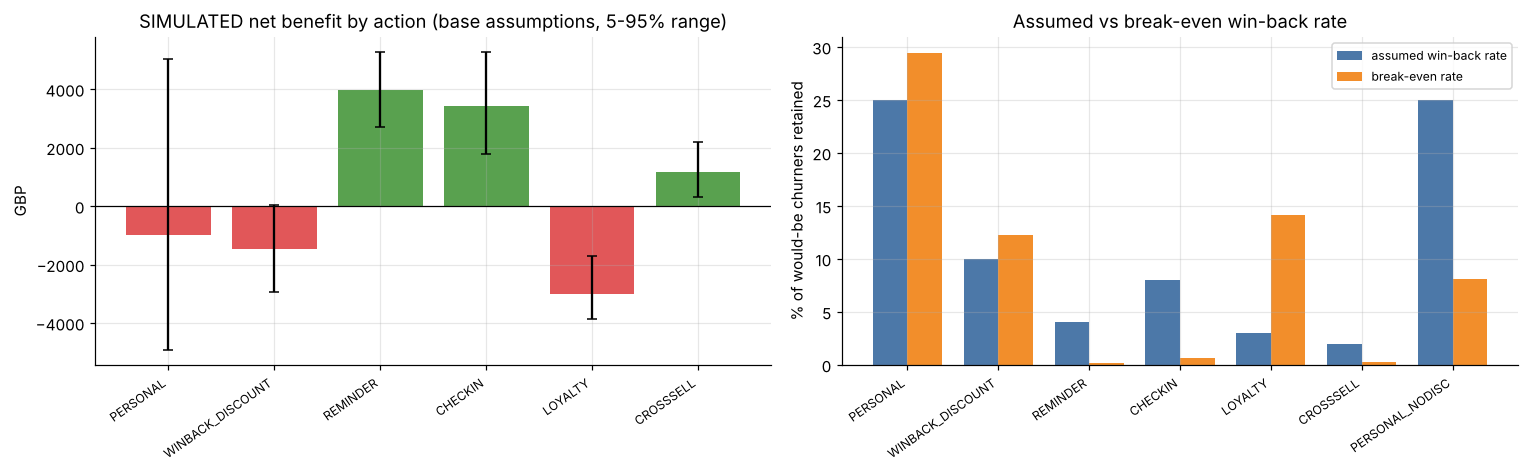

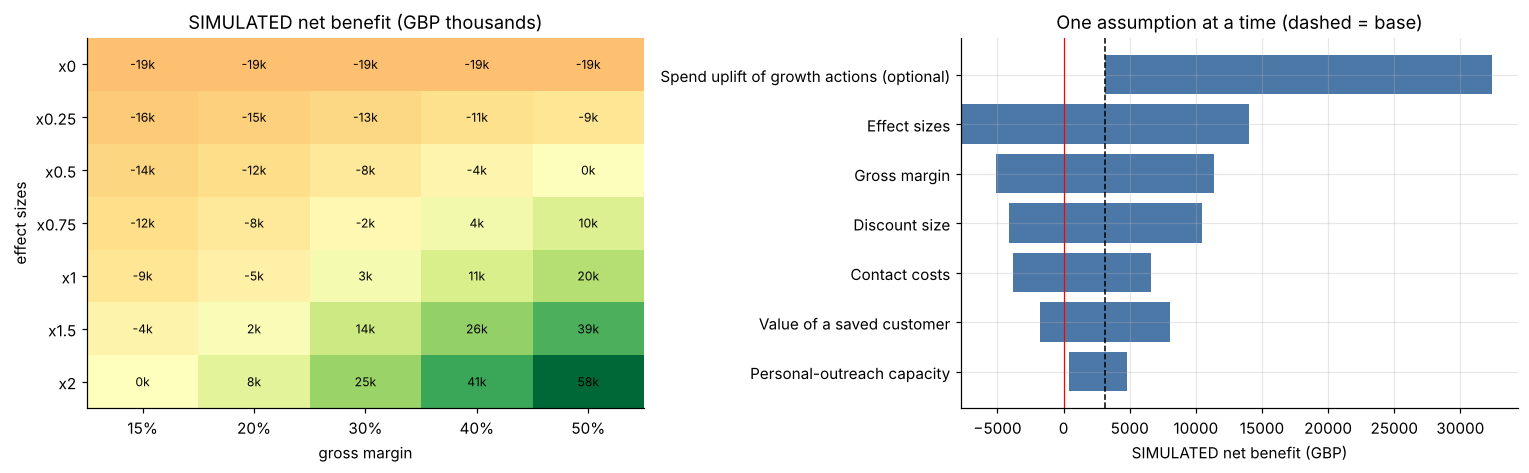

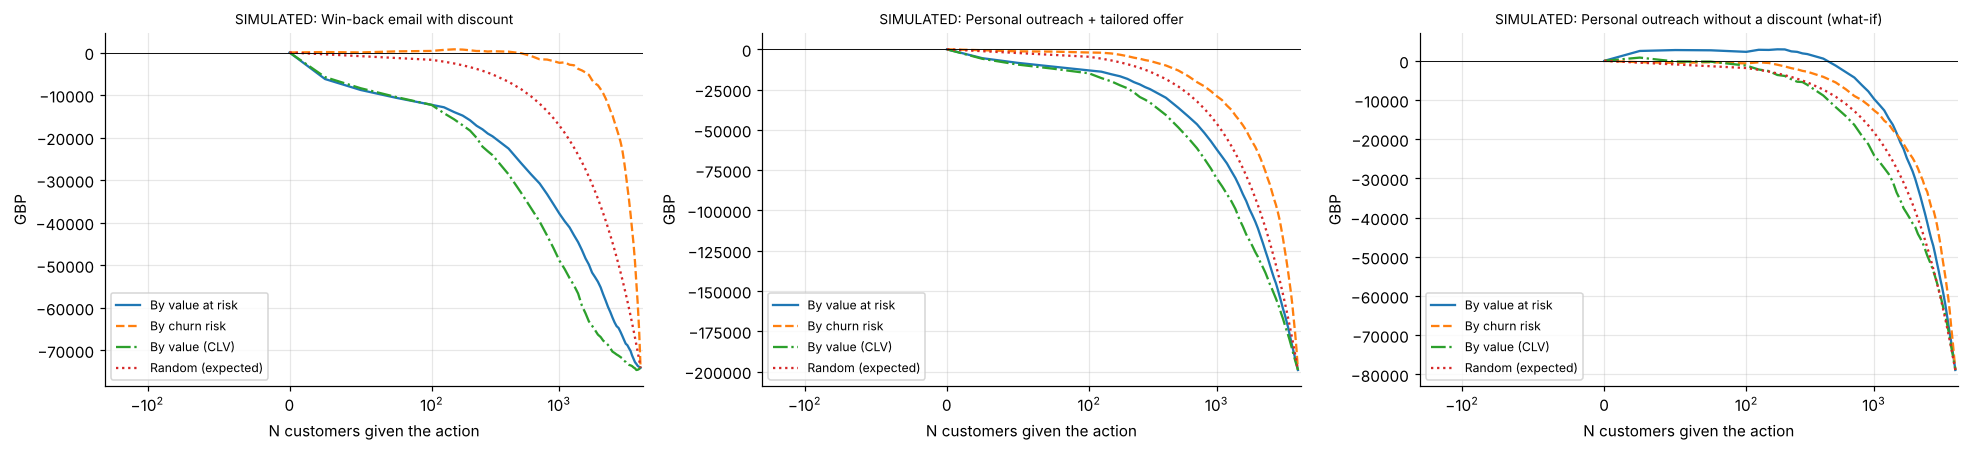

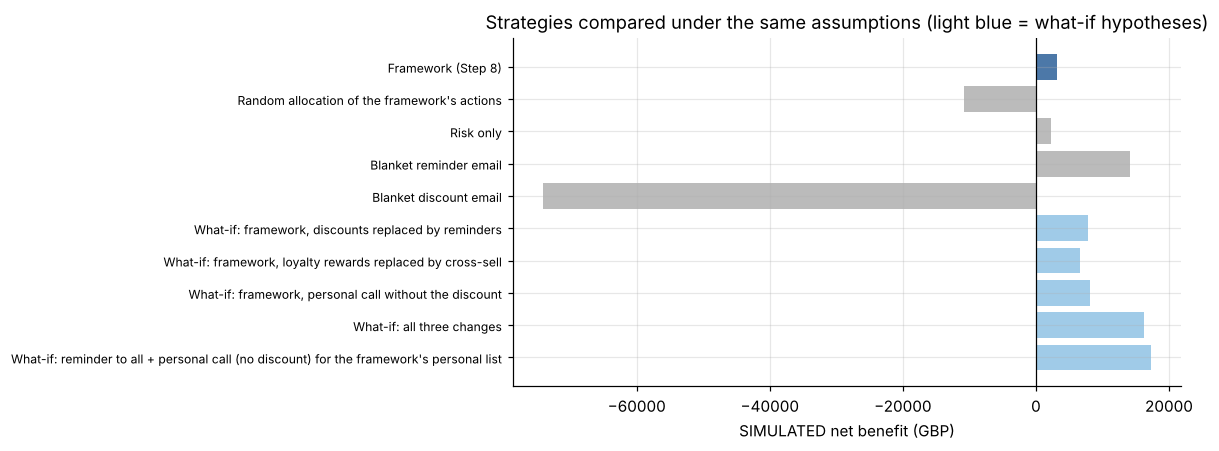

In [10]:
# ---- charts
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
names = [ACT.loc[a, "Action"] for a in ACT.index[:-1]]
m_ = mc.iloc[:-1]
ax[0].bar(range(len(m_)), m_["mean"], yerr=[m_["mean"] - m_["p5"], m_["p95"] - m_["mean"]], capsize=3,
          color=["#59A14F" if v > 0 else "#E15759" for v in m_["mean"]])
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xticks(range(len(m_))); ax[0].set_xticklabels(m_.index, rotation=35, ha="right", fontsize=8)
ax[0].set_ylabel("GBP"); ax[0].set_title("SIMULATED net benefit by action (base assumptions, 5-95% range)")
b_ = be.drop(index="MONITOR")
x_ = np.arange(len(b_)); w_ = 0.38
ax[1].bar(x_ - w_ / 2, b_["AssumedW"] * 100, w_, label="assumed win-back rate", color="#4C78A8")
ax[1].bar(x_ + w_ / 2, b_["BreakEvenW"].replace(np.inf, np.nan) * 100, w_, label="break-even rate", color="#F28E2B")
ax[1].set_xticks(x_); ax[1].set_xticklabels(b_.index, rotation=35, ha="right", fontsize=8); ax[1].set_ylabel("% of would-be churners retained"); ax[1].legend(fontsize=8)
ax[1].set_title("Assumed vs break-even win-back rate")
plt.tight_layout(); plt.savefig(FIG / "sim_by_action.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
im = ax[0].imshow(grid.to_numpy() / 1000, cmap="RdYlGn", aspect="auto", vmin=-np.abs(grid.to_numpy() / 1000).max(), vmax=np.abs(grid.to_numpy() / 1000).max()); ax[0].grid(False)
ax[0].set_xticks(range(len(MARGINS))); ax[0].set_xticklabels([f"{m:.0%}" for m in MARGINS]); ax[0].set_xlabel("gross margin")
ax[0].set_yticks(range(len(SCALES))); ax[0].set_yticklabels([f"x{s:g}" for s in SCALES]); ax[0].set_ylabel("effect sizes")
for i in range(len(SCALES)):
    for j in range(len(MARGINS)):
        ax[0].text(j, i, f"{grid.iloc[i, j] / 1000:,.0f}k", ha="center", va="center", fontsize=8)
ax[0].set_title("SIMULATED net benefit (GBP thousands)")
for k, r in tornado.iloc[::-1].reset_index(drop=True).iterrows():
    lo_, hi_ = sorted([r["NetAtLow"], r["NetAtHigh"]])
    ax[1].barh(k, hi_ - lo_, left=lo_, color="#4C78A8")
ax[1].set_yticks(range(len(tornado))); ax[1].set_yticklabels(tornado["Assumption"].iloc[::-1])
ax[1].axvline(base_net, color="k", ls="--", lw=1); ax[1].axvline(0, color="red", lw=0.8)
ax[1].set_xlabel("SIMULATED net benefit (GBP)"); ax[1].set_title("One assumption at a time (dashed = base)")
plt.tight_layout(); plt.savefig(FIG / "sim_sensitivity.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for a_, axx in zip(TARGET_ACTIONS, ax):
    t = targeting[targeting["Action"] == a_]
    for name, st in [("By value at risk", "-"), ("By churn risk", "--"), ("By value (CLV)", "-."), ("Random (expected)", ":")]:
        tt = t[t["Targeting"] == name]
        axx.plot(tt["N"], tt["Net"], st, label=name)
    axx.axhline(0, color="k", lw=0.6); axx.set_xscale("symlog", linthresh=100); axx.set_xlabel("N customers given the action"); axx.set_ylabel("GBP")
    axx.set_title(f"SIMULATED: {ACT_X.loc[a_, 'Action']}", fontsize=9); axx.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "sim_targeting.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.2))
s_ = strat[strat["Strategy"] != "No campaign"].reset_index(drop=True)
cols = ["#4C78A8" if "Framework (Step" in n else ("#BBBBBB" if "What-if" not in n else "#A0CBE8") for n in s_["Strategy"]]
ax.barh(range(len(s_))[::-1], s_["Net"], color=cols)
ax.set_yticks(range(len(s_))[::-1]); ax.set_yticklabels(s_["Strategy"], fontsize=8); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("SIMULATED net benefit (GBP)"); ax.set_title("Strategies compared under the same assumptions (light blue = what-if hypotheses)")
plt.tight_layout(); plt.savefig(FIG / "sim_strategies.png", dpi=120); plt.show()

## 9. Save the results

In [11]:
base.reset_index().to_csv(DATA / "simulation_by_action.csv", index=False)
be_out = be.reset_index()
be_out.to_csv(DATA / "simulation_breakeven.csv", index=False)
sens = pd.concat([grid.reset_index().rename(columns={"index": "EffectScale"}).assign(Table="grid_net_by_effect_scale_and_margin"),
                  tornado.assign(Table="tornado_one_at_a_time")], ignore_index=True)
sens.to_csv(DATA / "simulation_sensitivity.csv", index=False)
strat.to_csv(DATA / "simulation_strategies.csv", index=False)
settings = {"label": "SIMULATED, NOT MEASURED", "gross_margin": GROSS_MARGIN, "revenue_floor": REVENUE_FLOOR, "n_sims": N_SIMS,
            "effects_assumed": EFFECTS.reset_index().to_dict(orient="records"), "step8_settings": S8,
            "discount_assumption": "every contacted customer who buys uses the discount on one typical order"}
(MODELS / "simulation_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
for f in ("simulation_by_action.csv", "simulation_breakeven.csv", "simulation_sensitivity.csv", "simulation_strategies.csv", "simulation_targeting.csv"):
    print(f"saved data/{f}")
print("saved models/simulation_settings.json")

saved data/simulation_by_action.csv
saved data/simulation_breakeven.csv
saved data/simulation_sensitivity.csv
saved data/simulation_strategies.csv
saved data/simulation_targeting.csv
saved models/simulation_settings.json


## 10. Summary of findings

In [12]:
f_ = strat.set_index("Strategy")
pos = [a for a in ACT.index[:-1] if base.loc[a, "Net"] > 0]
neg = [a for a in ACT.index[:-1] if base.loc[a, "Net"] < 0]


def best_t(action, name):
    t = targeting[(targeting["Action"] == action) & (targeting["Targeting"] == name)]
    r = t.loc[t["Net"].idxmax()]
    return int(r["N"]), r["Net"]


def at_n(action, name, n=50):
    return targeting[(targeting["Action"] == action) & (targeting["Targeting"] == name) & (targeting["N"] == n)]["Net"].iloc[0]


tor = tornado[~tornado["Assumption"].str.startswith("Spend uplift")].iloc[0]
upl = tornado[tornado["Assumption"].str.startswith("Spend uplift")].iloc[0]
lines = [
    f"MEASURED (1 Jul 2011 test snapshot): churn model ROC-AUC {roc_auc_score(y, p):.3f}, PR-AUC {average_precision_score(y, p):.3f}; contacting the top 20% by risk reaches {y[top20].sum() / y.sum():.0%} of churners (random 20%).",
    f"MEASURED: CLV model predicted/actual purchase days {allc.loc['2011-07-01', 'PurchaseRatio']:.2f} at the July 2011 cut-off but {allc.loc['2010-12-31', 'PurchaseRatio']:.2f} at December 2010; recommender {best} Precision@10 {disc_.loc[best, 'Precision@10 [95% CI]'].split(' ')[0]} vs popularity {disc_.loc['Popularity', 'Precision@10 [95% CI]'].split(' ')[0]}.",
    f"SIMULATED base scenario (retention effect only; assumed margin {GROSS_MARGIN:.0%}, assumed win-back rates, placeholder costs): framework net benefit {tot['Net']:,.0f} (5-95% range {lo:,.0f} to {hi:,.0f}), {tot['Net'] / cost_tot:.2f} per GBP 1 spent; positive in {(sim_total > 0).mean():.0%} of runs.",
    "Actions that pay under the assumed win-back rates: " + (", ".join(pos) or "none") + ". Below break-even: " + (", ".join(neg) or "none") + ".",
] + [f"Break-even win-back rate, {be.loc[a, 'ActionName']}: {be.loc[a, 'BreakEvenW']:.1%} against {be.loc[a, 'AssumedW']:.1%} assumed." for a in ("PERSONAL", "PERSONAL_NODISC", "WINBACK_DISCOUNT", "LOYALTY", "REMINDER")] + [
    f"Sensitivity: the largest effect among the core assumptions is '{tor['Assumption']}' (net {tor['NetAtLow']:,.0f} to {tor['NetAtHigh']:,.0f}); with effects x0 the campaign loses {-grid.loc['effects x0', 'margin 30%']:,.0f}. "
    f"If the optional spend uplift of growth actions were real, net would be {upl['NetAtHigh']:,.0f} instead of {upl['NetAtLow']:,.0f}: it is a very influential assumption that is not part of the base.",
    "Targeting at N = 50 (simulated net): " + "; ".join(
        f"{ACT_X.loc[a, 'Action']}: value at risk {at_n(a, 'By value at risk'):,.0f}, churn risk {at_n(a, 'By churn risk'):,.0f}, CLV {at_n(a, 'By value (CLV)'):,.0f}, random {at_n(a, 'Random (expected)'):,.0f}" for a in TARGET_ACTIONS) + ".",
    f"Against alternatives (simulated net): framework {f_.loc['Framework (Step 8)', 'Net']:,.0f}; random allocation of the same actions {f_.loc['Random allocation of the framework' + chr(39) + 's actions', 'Net']:,.0f}; "
    f"risk only {f_.loc['Risk only', 'Net']:,.0f}; blanket reminder {f_.loc['Blanket reminder email', 'Net']:,.0f}; blanket discount {f_.loc['Blanket discount email', 'Net']:,.0f}. The framework beats random allocation in {better.mean():.0%} of reshuffles.",
    f"What-if (hypotheses, not validated): personal call without discount {f_.loc['What-if: framework, personal call without the discount', 'Net']:,.0f}; discounts replaced by reminders {f_.loc['What-if: framework, discounts replaced by reminders', 'Net']:,.0f}; "
    f"all three changes {f_.loc['What-if: all three changes', 'Net']:,.0f}; lean design (reminder to all + no-discount personal call) {f_.loc[[i for i in f_.index if i.startswith('What-if: reminder to all')][0], 'Net']:,.0f}.",
    "ALL retention results are simulated from assumed effects; real effectiveness requires a controlled test (a randomly chosen group is contacted, another is held back).",
]
print("KEY FINDINGS")
print("=" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
Path("simulation_summary.txt").write_text("\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)), encoding="utf-8")
print("\nSaved simulation_summary.txt")

KEY FINDINGS
1. MEASURED (1 Jul 2011 test snapshot): churn model ROC-AUC 0.775, PR-AUC 0.696; contacting the top 20% by risk reaches 31% of churners (random 20%).
2. MEASURED: CLV model predicted/actual purchase days 0.98 at the July 2011 cut-off but 1.59 at December 2010; recommender Matrix factorisation (SVD) Precision@10 0.087 vs popularity 0.049.
3. SIMULATED base scenario (retention effect only; assumed margin 30%, assumed win-back rates, placeholder costs): framework net benefit 3,140 (5-95% range -1,876 to 9,678), 0.15 per GBP 1 spent; positive in 81% of runs.
4. Actions that pay under the assumed win-back rates: REMINDER, CHECKIN, CROSSSELL. Below break-even: PERSONAL, WINBACK_DISCOUNT, LOYALTY.
5. Break-even win-back rate, Personal outreach + tailored offer: 29.5% against 25.0% assumed.
6. Break-even win-back rate, Personal outreach without a discount (what-if): 8.1% against 25.0% assumed.
7. Break-even win-back rate, Win-back email with discount: 12.2% against 10.0% assumed.


## What this does and does not show

**What the simulation supports**
* **Which assumptions matter.** The net benefit moves mostly with the assumed win-back rates, the margin and the discount size (section 6). The **break-even table** (section 5) is the most transferable result: it states how effective each action must be to pay off, which can be judged against experience or a pilot.
* **Cheap actions are robust, costly ones are not.** Reminders, check-ins and cross-sell emails pay off at tiny win-back rates; discounts, loyalty rewards and personal calls need much larger ones. A discount is a cost for *every* customer who buys, including those who would have bought anyway, and it grows with order size, which is why it weighs heavily for large customers.
* **Targeting depends on the action** (section 7): value at risk captures the most lost revenue (Step 8, section 6), but once the cost of discounts is counted, the best targeting rule can differ. The printed summary shows what the numbers say for each action.

**What it cannot show**
* **Whether any action works.** Every effect size is an assumption. The only way to measure effectiveness is a **controlled pilot**: contact a random part of the at-risk customers, hold out the rest, and compare returns after 150 days.
* **Revenue of the churners had they stayed** is estimated from the Step 6 model, not observed. The estimate was checked against the spend of customers who did return (section 3) and is reasonable on average.
* **Costs, margin and the discount behaviour are placeholders.** Only the 150-day window is valued, which understates the worth of keeping a customer; on the other side, the discount is assumed to be used by every buyer.
* **Growth effects** (customers spending more because of an offer) are excluded from the base scenario because they are not retention effects and are very influential; section 6 shows what they would change.
* **Interactions** (customers contacted by several campaigns, contact fatigue, customers who return later) are ignored.
* The what-if variants in section 8 were suggested by this same simulation, so their advantage is optimistic and has to be tested separately.
* One snapshot (1 July 2011): results can differ in other periods, and a few very large customers influence the totals.